### Kernels and responses for clusters — outlier filtering evaluation

Pulled from `figure_5_supplemental.ipynb`. Purpose: compare how the two different outlier-removal methods used by `plot_mean_cluster_response_profiles` and `plot_cluster_properties_combined` affect which cells are included and how the plots look.

Plots included: kernel weights for clusters, kernel heatmaps, `plot_cluster_properties_combined`, and `plot_mean_cluster_response_profiles`.

## Data Loading

#### Imports & setup

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # non-interactive backend
import matplotlib.pyplot as plt
import pickle
import seaborn as sns
import scipy.stats as stats
from scipy.special import comb

import visual_behavior.data_access.loading as loading
import visual_behavior.data_access.utilities as utilities
import visual_behavior.visualization.utils as utils

from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

import visual_behavior.visualization.ophys.platform_paper_figures as ppf
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse

%load_ext autoreload
%autoreload 2
%matplotlib inline

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/xarray/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain 

In [3]:
sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 1})

experience_level_colors = utils.get_experience_level_colors()
cre_line_colors = utils.get_cre_line_colors()
experience_levels = utils.get_new_experience_levels()
cell_types = utils.get_cell_types()

glm_version = '24_events_all_L2_optimize_by_session'

# Main clustering parameters
n_clusters = 14
n_clusters_familiar = 10  # For familiar-only clustering control

# Create save directories
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_5_supplemental')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

#### Metadata tables

In [4]:
# Cache directory
platform_cache_dir = loading.get_platform_analysis_cache_dir()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, "all_ophys_experiments_table.csv"), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_ophys_experiments_table.csv"), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_ophys_cells_table.csv"), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_matched_ophys_cells_table.csv"), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()
palette = utils.get_experience_level_colors()


#### GLM & clustering results

In [5]:
data_dir = loading.get_clustering_results_dir()

# Load clustering results (main clustering with n_clusters=14)
feature_matrix = pd.read_hdf(os.path.join(data_dir, 'clustering_feature_matrix.h5'), key='df')
feature_matrix = feature_matrix.rename(columns={'all-images': 'images', 'behavioral': 'behavior'})

cluster_meta = pd.read_hdf(os.path.join(data_dir, 'cluster_metadata_' + str(n_clusters) + '_clusters.h5'), key='df')

original_feature_matrix = feature_matrix.copy()
original_cluster_meta = cluster_meta.copy()

cluster_order = np.sort(cluster_meta.cluster_id.unique())

# Load GLM results for coding score analysis
glm_results_dir = loading.get_glm_results_dir()
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'across_session_normalized_platform_results_pivoted.h5'), key='df')

# Get GLM weights
weights_df = pd.read_hdf(os.path.join(loading.get_glm_results_dir(), 'platform_results_weights_df.h5'), key='df')
weights_df['experience_level'] = [utils.convert_experience_level(experience_level) for experience_level in weights_df.experience_level.values]
weights_df = weights_df.merge(platform_experiments[['cell_type']], on='ophys_experiment_id', how='left')
weights_df = weights_df.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id', how='left')

run_params = pd.read_pickle(os.path.join(loading.get_glm_results_dir(), glm_version + '_run_params.pkl'))
kernels = run_params['kernels']



#### Multi-Session Dataframes

In [6]:
# Data type configuration
data_type = 'events'
interpolate = True
output_sampling_rate = 30
inclusion_criteria = 'platform_experiment_table'


conditions = ['cell_specimen_id', 'is_change']
multi_session_df = loading.get_multi_session_df_for_conditions(
    data_type,
    event_type='all',
    conditions=conditions,
    inclusion_criteria=inclusion_criteria,
    interpolate=interpolate,
    output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

# Separate into change and non-change responses
change_mdf = multi_session_df[multi_session_df.is_change == True]
change_mdf = change_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

image_mdf = multi_session_df[multi_session_df.is_change == False]
image_mdf = image_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

# Omission responses
conditions = ['cell_specimen_id', 'omitted']
omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type,
    event_type='all',
    conditions=conditions,
    inclusion_criteria=inclusion_criteria,
    interpolate=interpolate,
    output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

omission_mdf = omission_mdf[omission_mdf.omitted == True]
omission_mdf = omission_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

# # Remove outliers
# threshold_percentile = 99.8  # for removing outliers for pl
# image_mdf, image_outliers = processing.remove_outliers(image_mdf, threshold_percentile)
# change_mdf, change_outliers = processing.remove_outliers(change_mdf, threshold_percentile)
# omission_mdf, omission_outliers = processing.remove_outliers(omission_mdf, threshold_percentile)

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


## Kernel weights for clusters

All cells (no cell-type split):

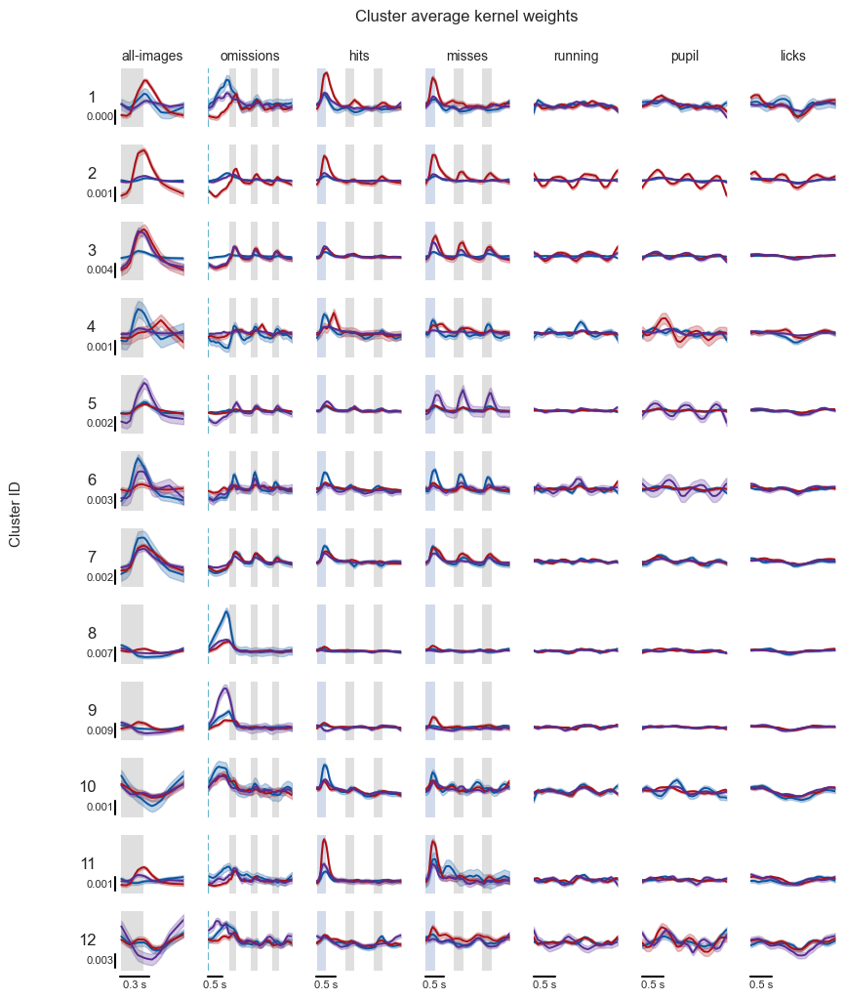

In [6]:
kernels_for_overlay_plot = ['all-images', 'omissions', 'hits', 'misses', 'running', 'pupil', 'licks']

fig, axes = plotting.plot_cluster_kernel_overlays_by_experience(
    weights_df,
    run_params,
    kernels_to_plot=None,
    linewidth=1.4,
    share_y_across="row",
    cell_type=None,
    show_all_clusters=False,
    min_cluster_fraction=0,
)
plt.show()

Separate plot per cell type:

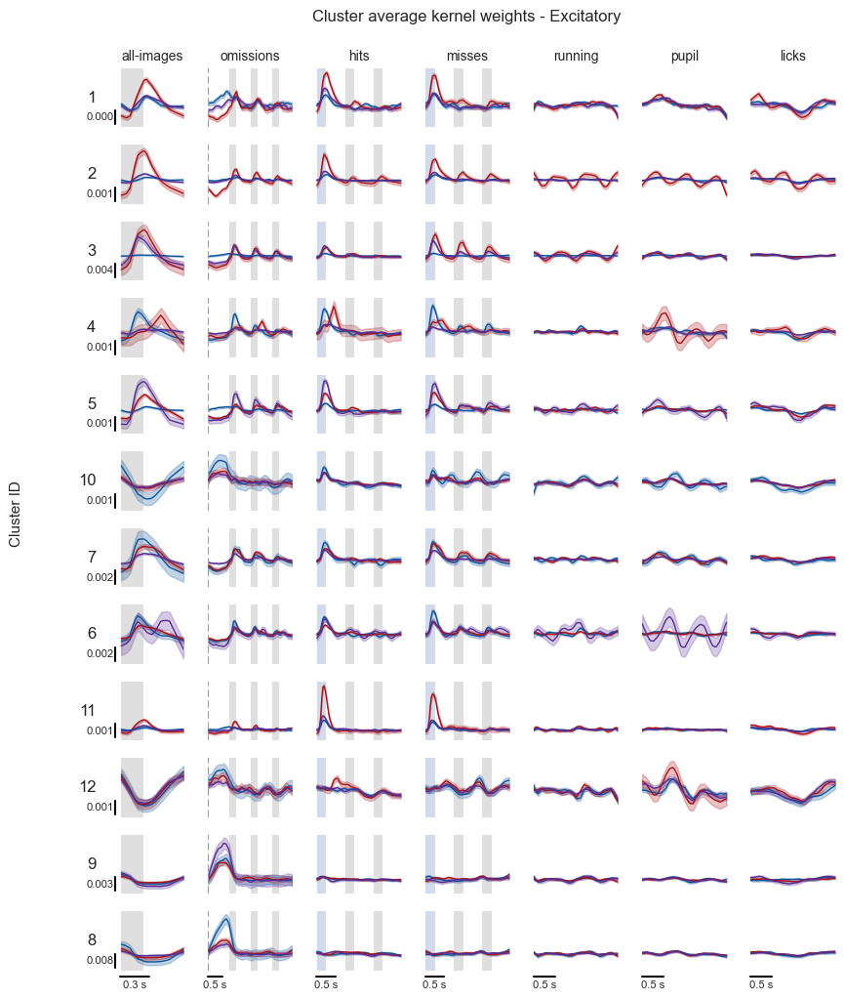

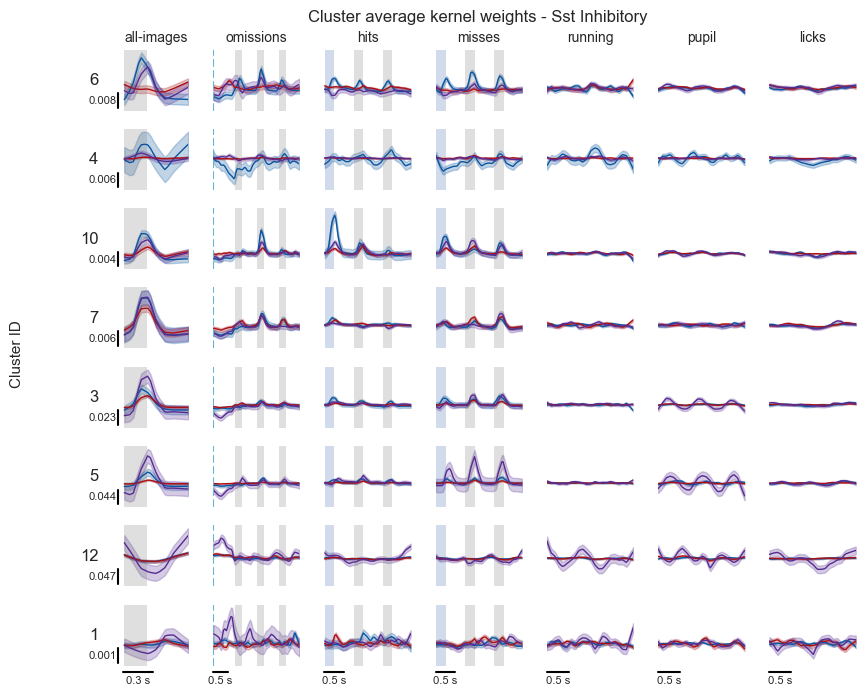

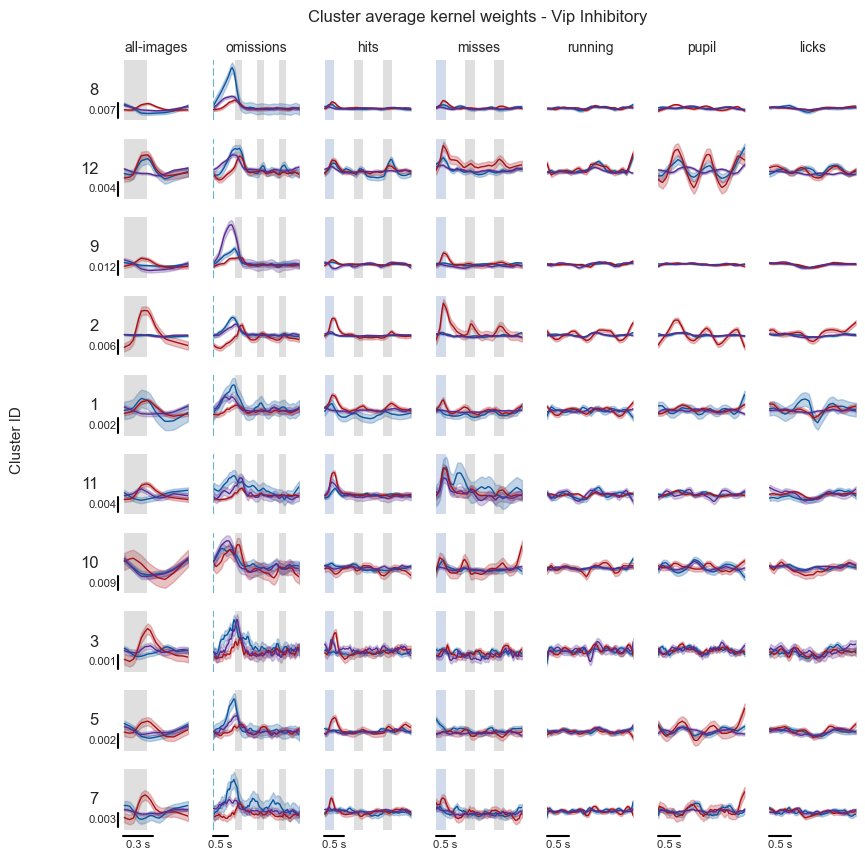

In [7]:
kernels_for_overlay_plot = ['all-images', 'omissions', 'hits', 'misses', 'running', 'pupil', 'licks']

for cell_type in cell_types:
    fig, axes = plotting.plot_cluster_kernel_overlays_by_experience(
        weights_df,
        run_params,
        kernels_to_plot=None,
        linewidth=1,
        share_y_across="row",
        cell_type=cell_type,
        show_all_clusters=False,
        min_cluster_fraction=0.04,
    )
    plt.show()

## Kernel heatmaps

Note: `prepare_and_plot_concatenated_image_kernels` does **no** outlier removal — every cell in each cluster appears as a row. This makes the heatmaps a useful reference for seeing how many cells the trace-based methods drop.

Prepared 'concatenated_image': plotted length=185, kept 3872/3901 cells with complete experience coverage.


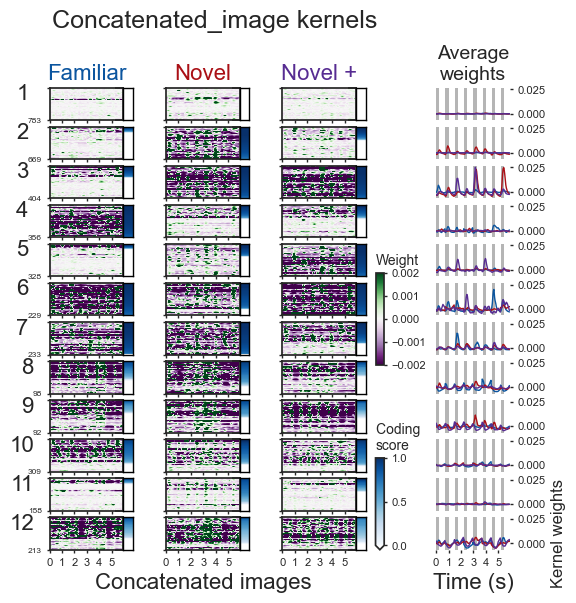

In [8]:
# Example usage: build data + plot all cells in one call
reformatted_weights_df, melted_weights_df, run_params_tmp = plotting.prepare_and_plot_concatenated_image_kernels(
    kernel_names=['concatenated_images'],
    weights_df=weights_df,
    run_params=run_params,
    experience_levels=experience_levels,
    row_condition='cluster_id',
    col_condition='experience_level',
    vmax=0.002,
    xlabel='Concatenated images',
    suptitle=None,
    plot=True,
    split_by_cell_type=False,
)

Prepared 'concatenated_image': plotted length=185, kept 3872/3901 cells with complete experience coverage.


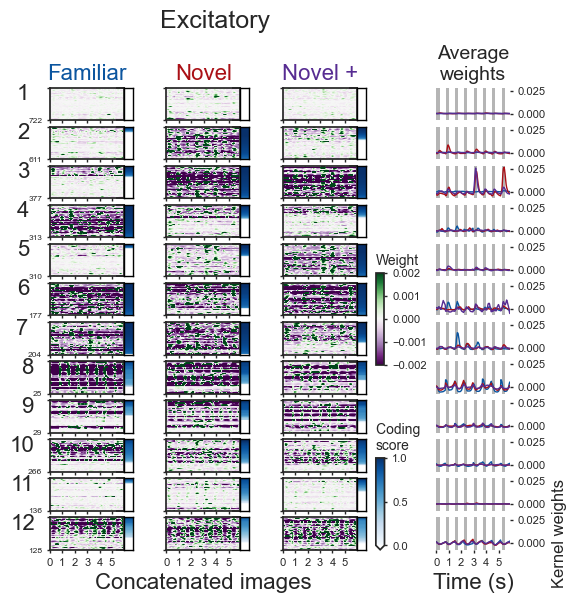

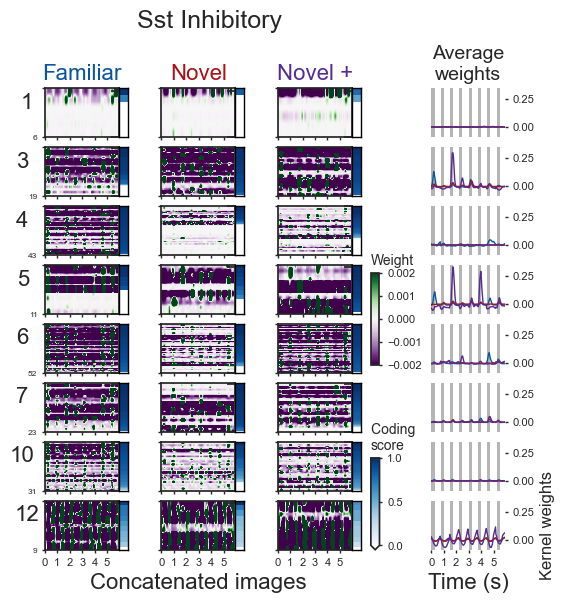

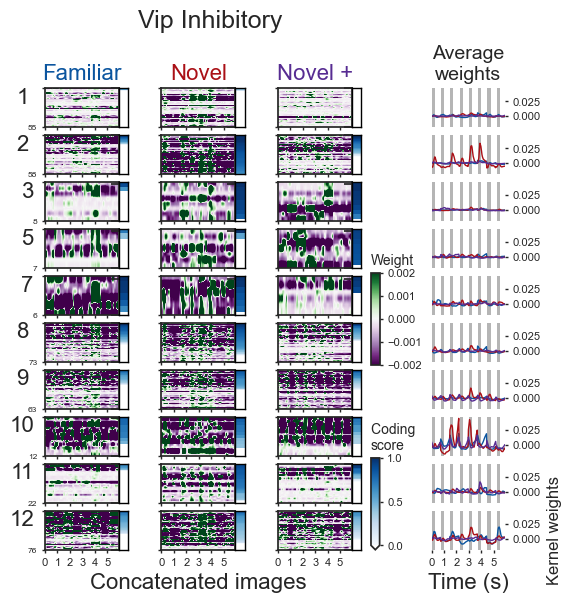

In [9]:
# Example usage: build data + plot all cells in one call
reformatted_weights_df, melted_weights_df, run_params_tmp = plotting.prepare_and_plot_concatenated_image_kernels(
    kernel_names=['concatenated_images'],
    weights_df=weights_df,
    run_params=run_params,
    experience_levels=experience_levels,
    row_condition='cluster_id',
    col_condition='experience_level',
    vmax=0.002,
    xlabel='Concatenated images',
    suptitle=None,
    plot=True,
    split_by_cell_type=True,
)

Prepared 'omissions': plotted length=93, kept 3872/3901 cells with complete experience coverage.


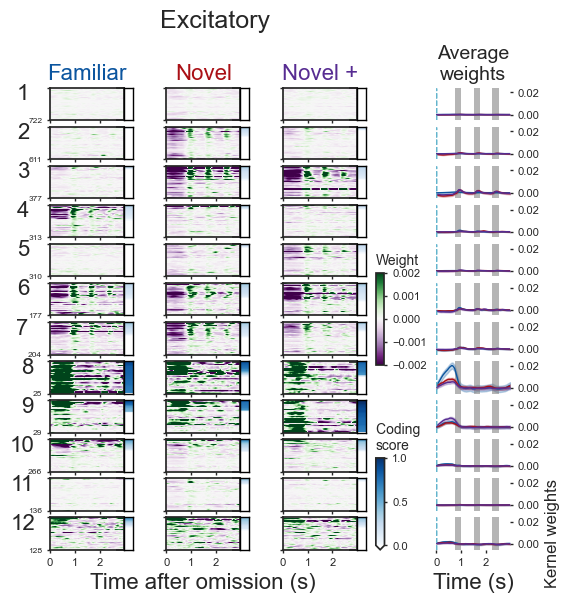

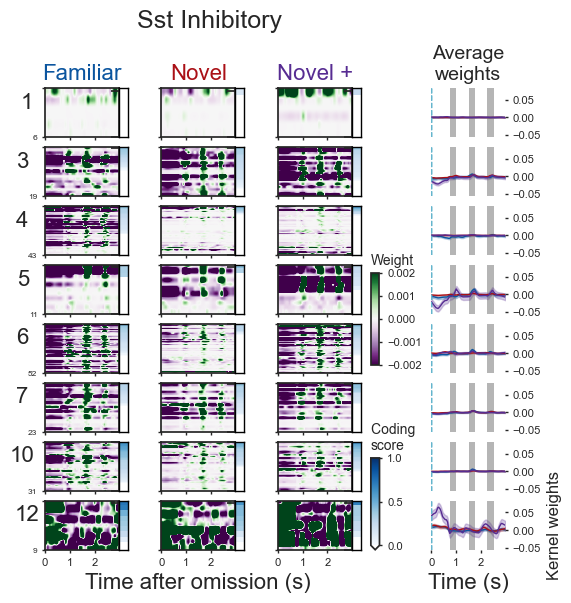

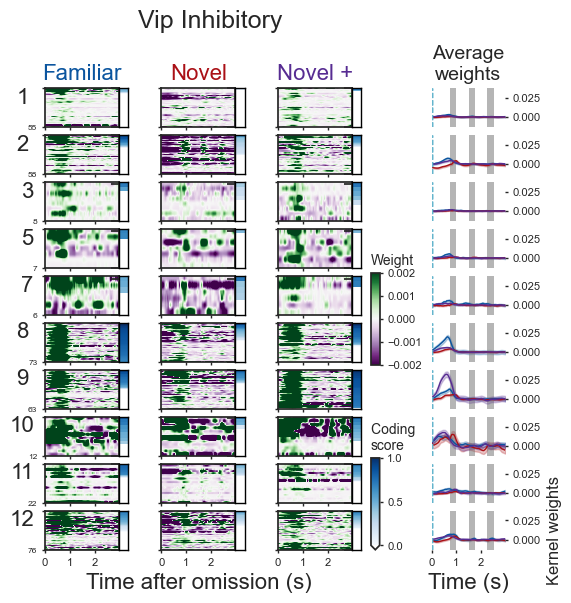

In [10]:
# Example usage: build data + plot all cells in one call
reformatted_weights_df, melted_weights_df, run_params_tmp = plotting.prepare_and_plot_concatenated_image_kernels(
    kernel_names=['omissions'],
    weights_df=weights_df,
    run_params=run_params,
    experience_levels=experience_levels,
    row_condition='cluster_id',
    col_condition='experience_level',
    vmax=0.002,
    xlabel='Time after omission (s)',
    suptitle=None,
    plot=True,
    split_by_cell_type=True,
)

Prepared 'hits_misses': plotted length=140, kept 3857/3901 cells with complete experience coverage.


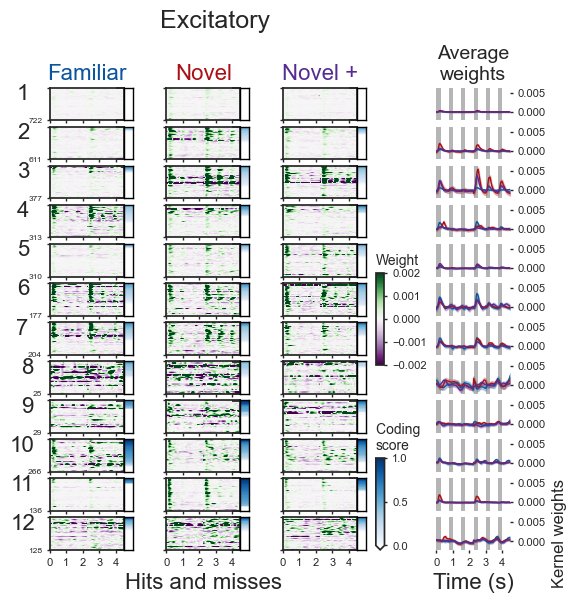

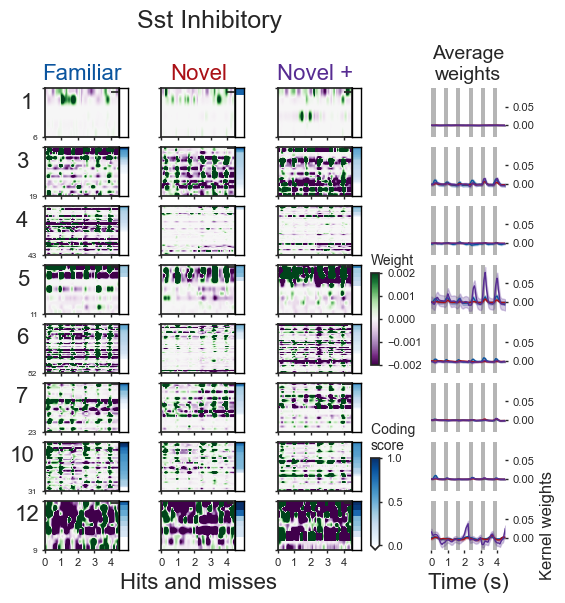

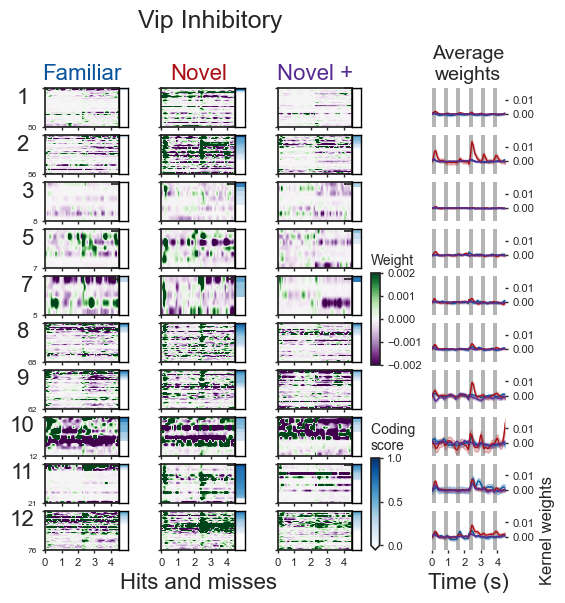

In [11]:
# Example usage: build data + plot all cells in one call
reformatted_weights_df, melted_weights_df, run_params_tmp = plotting.prepare_and_plot_concatenated_image_kernels(
    kernel_names=['hits', 'misses'],
    weights_df=weights_df,
    run_params=run_params,
    experience_levels=experience_levels,
    row_condition='cluster_id',
    col_condition='experience_level',
    vmax=0.002,
    xlabel='Hits and misses',
    suptitle=None,
    plot=True,
    split_by_cell_type=True,
)

Prepared 'licks_running_pupil': plotted length=186, kept 3829/3901 cells with complete experience coverage.


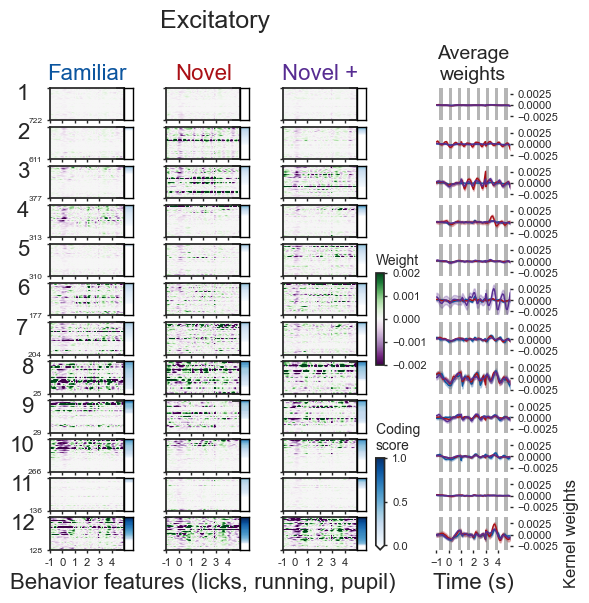

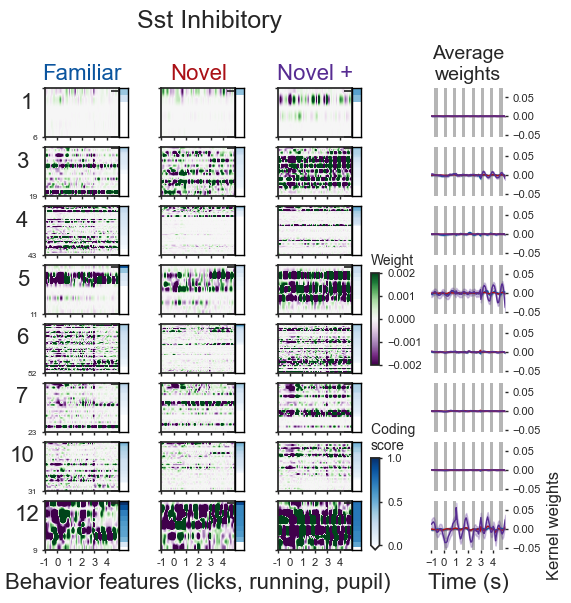

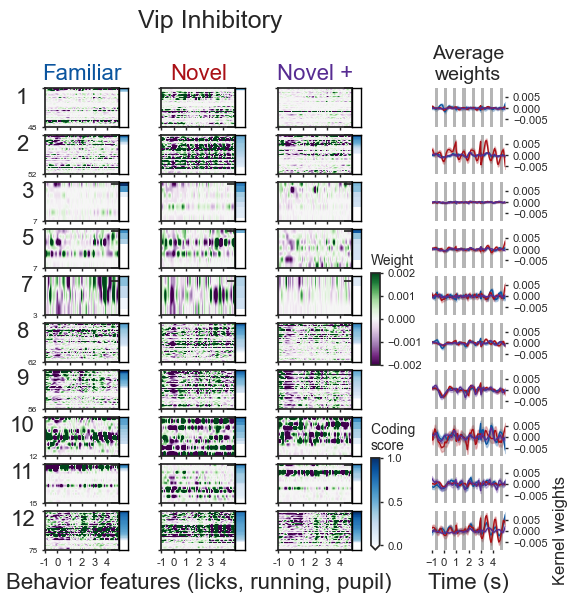

In [12]:
# Example usage: build data + plot all cells in one call
reformatted_weights_df, melted_weights_df, run_params_tmp = plotting.prepare_and_plot_concatenated_image_kernels(
    kernel_names=['licks', 'running', 'pupil'],
    weights_df=weights_df,
    run_params=run_params,
    experience_levels=experience_levels,
    row_condition='cluster_id',
    col_condition='experience_level',
    vmax=0.002,
    xlabel='Behavior features (licks, running, pupil)',
    suptitle=None,
    plot=True,
    split_by_cell_type=True,
)

## Coding scores & average responses

`plot_cluster_properties_combined` filters with `processing.remove_outliers` (percentile-based, on scalar mean_response & mean_baseline).

All cre lines combined:

12


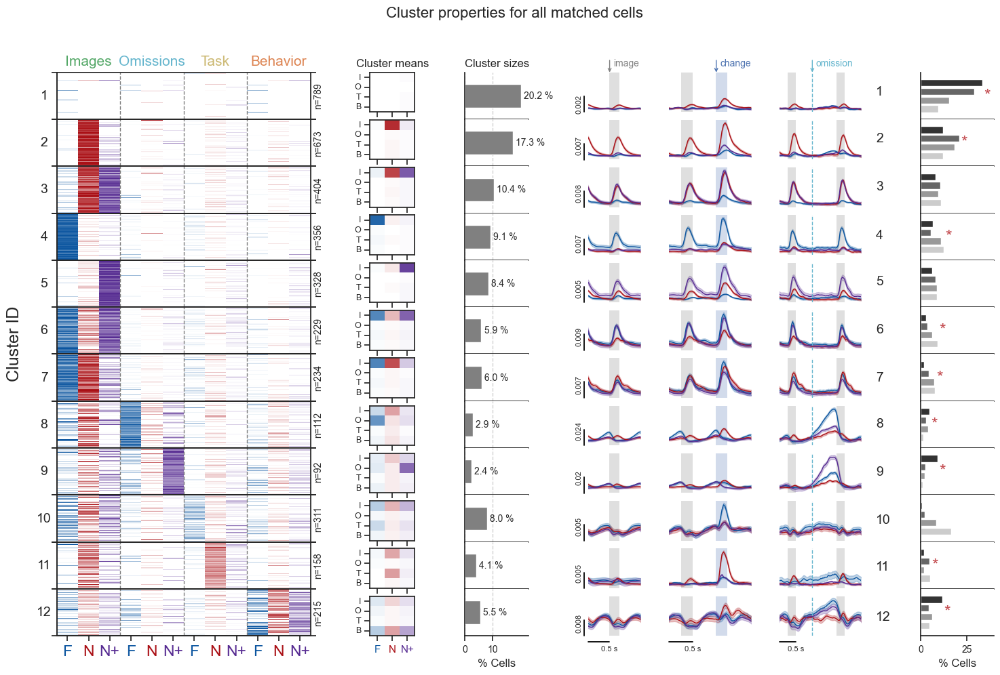

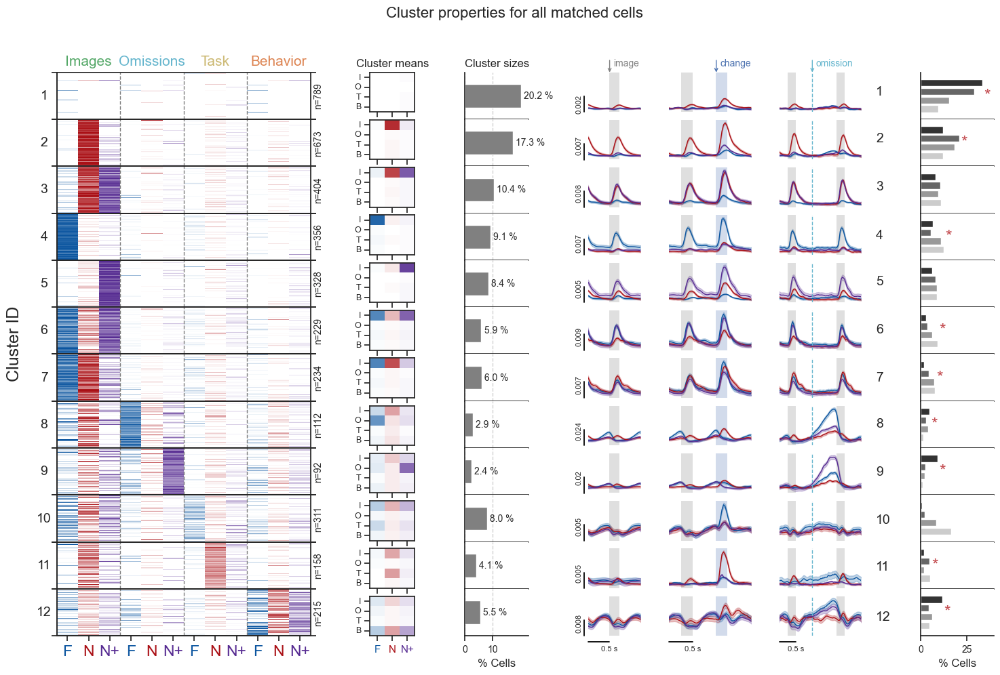

In [7]:
# All cre lines combined
tmp = cluster_meta.copy()
tmp['cre_line'] = 'all'

plotting.plot_cluster_properties_combined(
    tmp,
    feature_matrix,
    'all',
    image_mdf,
    change_mdf,
    omission_mdf,
    save_dir=save_dir, apply_peak_threshold=True)


By individual cre line:

12
6
7


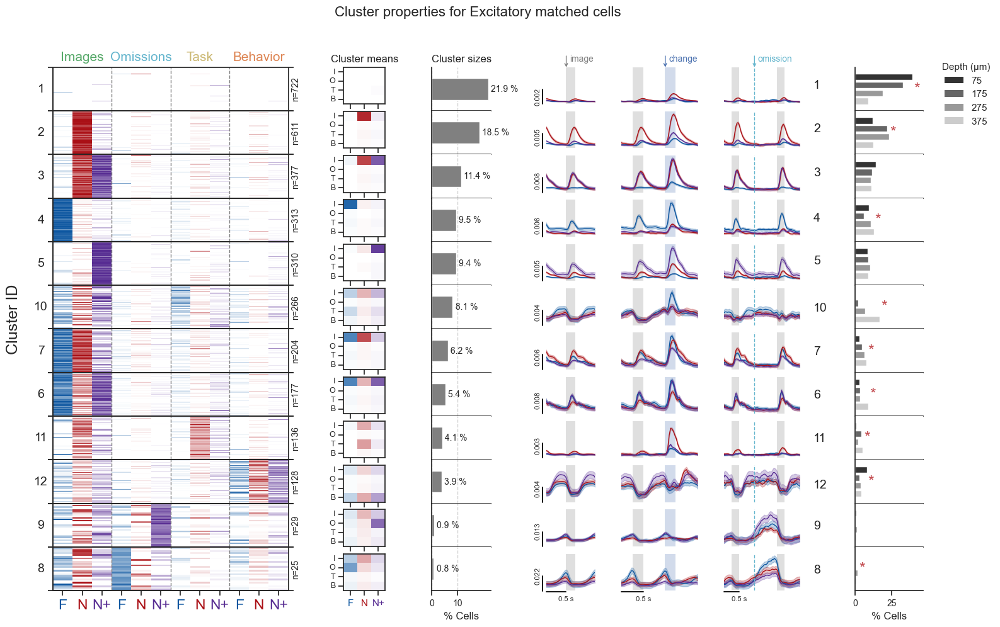

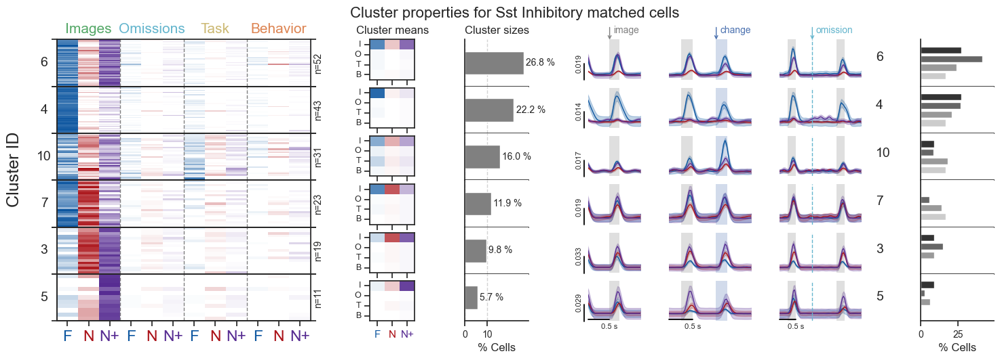

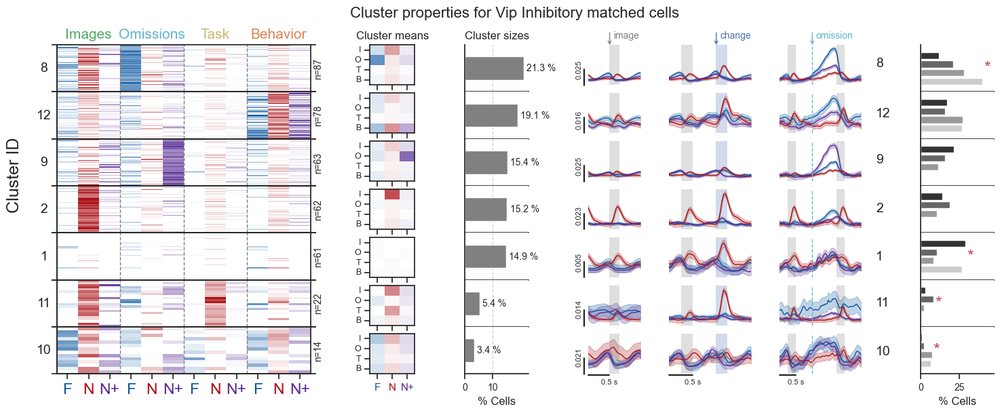

In [8]:

# By individual cre line
for cre_line in cre_lines:
    plotting.plot_cluster_properties_combined(
        cluster_meta,
        feature_matrix,
        cre_line,
        image_mdf,
        change_mdf,
        omission_mdf,
        save_dir=save_dir,
        sort_by='cluster_size', apply_peak_threshold=True)


## Mean cluster response profiles

`plot_mean_cluster_response_profiles` filters with `_drop_outlier_traces` (MAD-based, on the peak amplitude of each cell's mean response trace; `outlier_threshold=5`).

(<Figure size 560x420 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Cluster 5'}>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 10'}>],
        [<Axes: title={'center': 'Cluster 6'}>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 10'}>],
        [<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Cluster 9'}>,
         <Axes: title={'center': 'Cluster 8'}>,
         <Axes: title={'center': 'Cluster 11'}>]], dtype=object))

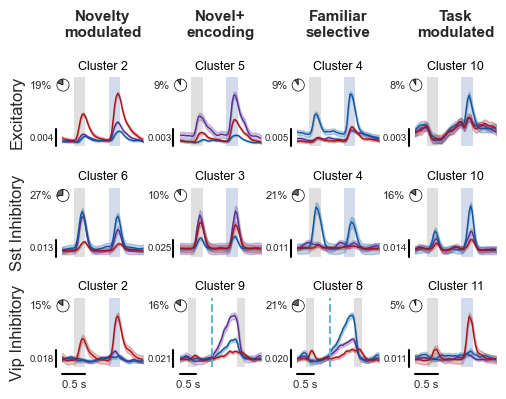

In [9]:
plotting.plot_mean_cluster_response_profiles(
    image_mdf,
    change_mdf,
    omission_mdf,
    linewidth=1,
    x_sb_seconds=0.5,
    apply_peak_threshold=True,
)


## Evaluating the two outlier-removal methods

The two functions filter cells in **fundamentally different ways**:

**Method A — `plot_mean_cluster_response_profiles` → `_drop_outlier_traces`**
- Quantity: peak absolute amplitude of each cell's *mean response trace* (`max(|trace|)`).
- Statistic: MAD-based robust z-score. Keep if `peak <= median + threshold * 1.4826 * MAD`.
- Threshold: `outlier_threshold=5` (≈5 robust SDs above the median).
- Scope: computed **separately for each (cell_type, cluster_id, experience_level)** group.
  The median/MAD adapt to each cluster's local distribution, and a cell can be kept in one
  experience level but dropped in another.

**Method B — `plot_cluster_properties_combined` → `processing.remove_outliers`**
- Quantity: scalar `mean_response` AND `mean_baseline`.
- Statistic: percentile threshold (99.8th) computed **per cre line**.
- Rule: a cell is an outlier only if `mean_response > p99.8` **AND** `mean_baseline > p99.8`
  (so cells with a big evoked response but normal baseline are *not* removed — this mostly
  targets tonically high / saturated cells).
- Plus a hard-coded list of 9 known-bad cells, always removed.
- Scope: removes the cell from the **entire dataframe** (every cluster & experience level).

Implications to watch for:
- Method A is **relative** and **local**: in a small cluster where most cells are quiet and a
  few are genuine strong responders, the MAD is tiny, so real responders can exceed
  `5*1.4826*MAD` and get dropped as "outliers" — i.e. it can remove meaningful signal.
- Method B is **absolute** and **conservative**: the AND-condition + 99.8th percentile removes
  very few cells (only globally extreme ones), so it rarely touches real signal but may leave
  in moderately large responders that still distort a small-cluster mean.

The cells below quantify and visualize the difference.

In [10]:
# --- Diagnostic helpers: replicate each method's drop logic, tracking cell IDs ---
# Assumptions:
#   * each row of *_mdf is one cell (cell_specimen_id) at one experience_level
#   * columns present: cell_specimen_id, cre_line, cell_type, cluster_id,
#     experience_level, mean_trace, mean_response, mean_baseline
import numpy as np, pandas as pd

def method_A_drops(mdf, outlier_threshold=5):
    """Method A (MAD on trace peak), applied per (cell_type, cluster_id, experience_level).
    Returns a df of rows it would DROP, with the group keys + peak value."""
    rows = []
    grp = mdf[mdf[['cluster_id','cell_type','experience_level']].notna().all(axis=1)]
    for (ct, cl, exp), g in grp.groupby(['cell_type','cluster_id','experience_level']):
        traces = [np.asarray(t) for t in g['mean_trace'].values
                  if t is not None and not (isinstance(t, float) and np.isnan(t))]
        if not traces:
            continue
        valid = g[[t is not None and not (isinstance(t, float) and np.isnan(t))
                   for t in g['mean_trace'].values]].copy()
        peak = np.array([np.nanmax(np.abs(np.asarray(t))) for t in valid['mean_trace'].values])
        med = np.median(peak); mad = np.median(np.abs(peak - med))
        if mad <= 0:
            continue
        keep = peak <= med + outlier_threshold * 1.4826 * mad
        dropped = valid.loc[~keep, ['cell_specimen_id','cre_line','cell_type',
                                    'cluster_id','experience_level']].copy()
        dropped['peak_abs'] = peak[~keep]
        rows.append(dropped)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=['cell_specimen_id','cre_line','cell_type','cluster_id','experience_level','peak_abs'])

def method_B_drops(mdf, threshold_percentile=99.8):
    """Method B (percentile on mean_response AND mean_baseline), per cre line, + hard-coded bad cells.
    Returns the set of cell_specimen_ids removed globally."""
    bad_cells = [1120091750,1120094237,1086580238,1086551540,1086553602,
                 1086514682,1086515397,1086673279,1086529704]
    outliers = set(bad_cells)
    for cre in mdf.cre_line.unique():
        c = mdf[mdf.cre_line == cre]
        r_thr = np.percentile(c.mean_response.values, threshold_percentile)
        b_thr = np.percentile(c.mean_baseline.values, threshold_percentile)
        outliers |= set(c[(c.mean_response > r_thr) & (c.mean_baseline > b_thr)]
                        .cell_specimen_id.unique())
    return outliers

# Run on change_mdf as an example (swap for image_mdf / omission_mdf as needed)
mdf = change_mdf
A = method_A_drops(mdf, outlier_threshold=5)
B = method_B_drops(mdf, threshold_percentile=99.8)

A_cells = set(A.cell_specimen_id.unique())
n_total = mdf.cell_specimen_id.nunique()
print(f"Total cells: {n_total}")
print(f"Method A drops {len(A)} (cell x experience) instances, "
      f"{len(A_cells)} unique cells ({100*len(A_cells)/n_total:.1f}%)")
print(f"Method B drops {len(B)} unique cells ({100*len(B)/n_total:.1f}%)")
print(f"Overlap (dropped by both): {len(A_cells & B)} cells")
print(f"Dropped by A only: {len(A_cells - B)} | by B only: {len(B - A_cells)}")


Total cells: 3895
Method A drops 680 (cell x experience) instances, 446 unique cells (11.5%)
Method B drops 19 unique cells (0.5%)
Overlap (dropped by both): 18 cells
Dropped by A only: 428 | by B only: 1


In [11]:
# Per-cluster breakdown: how many cells each method drops in each (cell_type, cluster)
per_cluster_A = (A.drop_duplicates(['cell_specimen_id','cell_type','cluster_id'])
                  .groupby(['cell_type','cluster_id']).size().rename('A_dropped'))
totals = (mdf.drop_duplicates('cell_specimen_id')
            .groupby(['cell_type','cluster_id']).size().rename('n_cells'))
B_df = mdf[mdf.cell_specimen_id.isin(B)].drop_duplicates('cell_specimen_id')
per_cluster_B = B_df.groupby(['cell_type','cluster_id']).size().rename('B_dropped')

summary = pd.concat([totals, per_cluster_A, per_cluster_B], axis=1).fillna(0).astype(int)
summary['A_frac'] = (summary.A_dropped / summary.n_cells).round(3)
summary['B_frac'] = (summary.B_dropped / summary.n_cells).round(3)
summary.sort_values('A_frac', ascending=False)


n_cells  A_dropped  B_dropped  A_frac  B_frac
cell_type      cluster_id                                               
Sst Inhibitory 5                11          4          0   0.364   0.000
Vip Inhibitory 2                62         17          1   0.274   0.016
               1                60         14          0   0.233   0.000
               11               22          5          1   0.227   0.045
Sst Inhibitory 12                9          2          2   0.222   0.222
               4                41          9          2   0.220   0.049
               7                23          5          0   0.217   0.000
               6                52         11          1   0.212   0.019
               3                19          4          0   0.211   0.000
Vip Inhibitory 9                63         11          0   0.175   0.000
               12               75         13          1   0.173   0.013
Sst Inhibitory 1                 6          1          1   0.167   0.167
Excitatory     8                25          4          0   0.160   0.000
               10              266         42          1   0.158   0.004
               3               377         52          3   0.138   0.008
               9                29          4          0   0.138   0.000
Sst Inhibitory 10               31          4          0   0.129   0.000
Excitatory     4               313         34          1   0.109   0.003
               6               177         19          1   0.107   0.006
Vip Inhibitory 8                87          9          0   0.103   0.000
Excitatory     5               310         31          1   0.100   0.003
               11              136         12          0   0.088   0.000
               12              128         11          0   0.086   0.000
               2               611         51          0   0.083   0.000
               1               722         60          0   0.083   0.000
               7               204         16          2   0.078   0.010
Vip Inhibitory 10               14          1          1   0.071   0.071
               5                 7          0          0   0.000   0.000
               7                 7          0          0   0.000   0.000
               3                 8          0          0   0.000   0.000

### Visualize kept vs. dropped traces

For a chosen (cell_type, cluster_id, experience_level), overlay the traces each method keeps vs.
drops. If the "dropped" traces look like genuine, structured responses (clean stimulus-locked
transients) rather than noisy/saturated artifacts, the filter is removing meaningful signal.

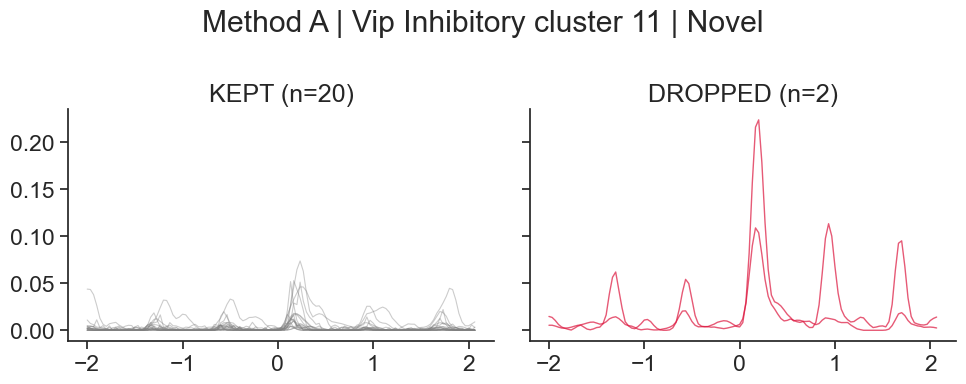

In [12]:
import matplotlib.pyplot as plt

def plot_kept_vs_dropped(mdf, cell_type, cluster_id, experience_level,
                         method='A', outlier_threshold=5, threshold_percentile=99.8):
    g = mdf[(mdf.cell_type==cell_type) & (mdf.cluster_id==cluster_id) &
            (mdf.experience_level==experience_level)].copy()
    g = g[[t is not None and not (isinstance(t,float) and np.isnan(t))
           for t in g['mean_trace'].values]]
    ts = np.asarray(g['trace_timestamps'].values[0])
    if method == 'A':
        peak = np.array([np.nanmax(np.abs(np.asarray(t))) for t in g['mean_trace'].values])
        med = np.median(peak); mad = np.median(np.abs(peak-med))
        keep = peak <= med + outlier_threshold*1.4826*mad if mad>0 else np.ones(len(g),bool)
    else:  # method B membership
        B = method_B_drops(mdf, threshold_percentile)
        keep = ~g.cell_specimen_id.isin(B).values

    fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)
    for t in g['mean_trace'].values[keep]:
        axes[0].plot(ts, np.asarray(t), color='gray', alpha=0.4, lw=0.8)
    for t in g['mean_trace'].values[~keep]:
        axes[1].plot(ts, np.asarray(t), color='crimson', alpha=0.7, lw=1.0)
    axes[0].set_title(f"KEPT (n={int(keep.sum())})")
    axes[1].set_title(f"DROPPED (n={int((~keep).sum())})")
    fig.suptitle(f"Method {method} | {cell_type} cluster {cluster_id} | {experience_level}")
    plt.tight_layout(); plt.show()

# Example — pick a cluster with high A_frac from the summary table above:
plot_kept_vs_dropped(change_mdf, 'Vip Inhibitory', 11, 'Novel', method='A')


#### All clusters × all cell types — kept vs. dropped, by experience level

One figure per cell type. Rows = clusters. Four columns:
1. **Kept** individual cell traces, colored by experience level
2. **Dropped** individual cell traces, colored by experience level
3. **Mean of kept cells only**, per experience level (±SEM)
4. **Mean of all cells** (kept + dropped), per experience level (±SEM)

Comparing columns 3 and 4 shows how much the dropped cells move the cluster mean — if the two
means look nearly identical, the filter is cosmetic; if column 4 has a peak that column 3 loses,
the dropped cells were carrying real signal. Each panel autoscales independently. Run once per method (A = MAD on trace peak; B = percentile on
mean_response/baseline).

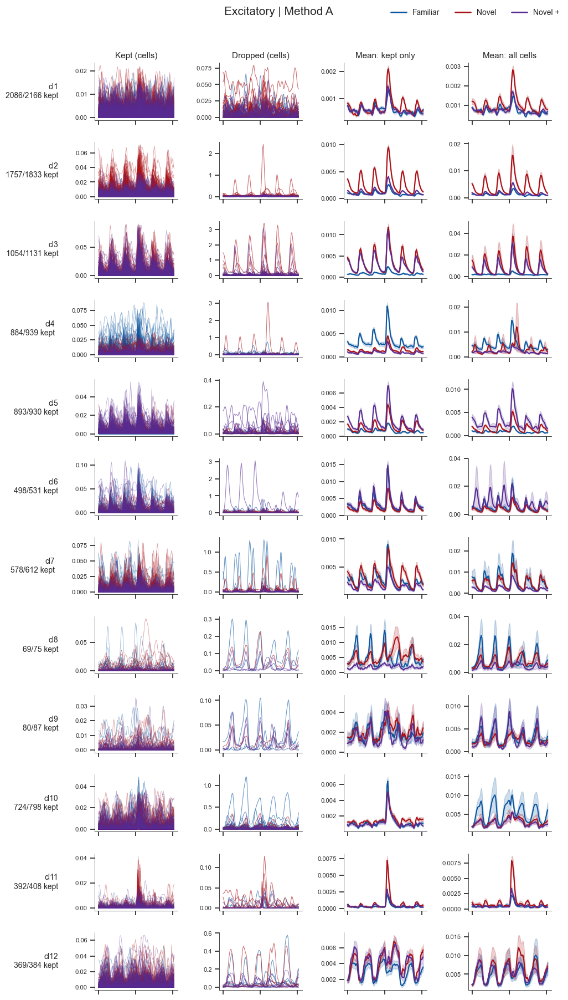

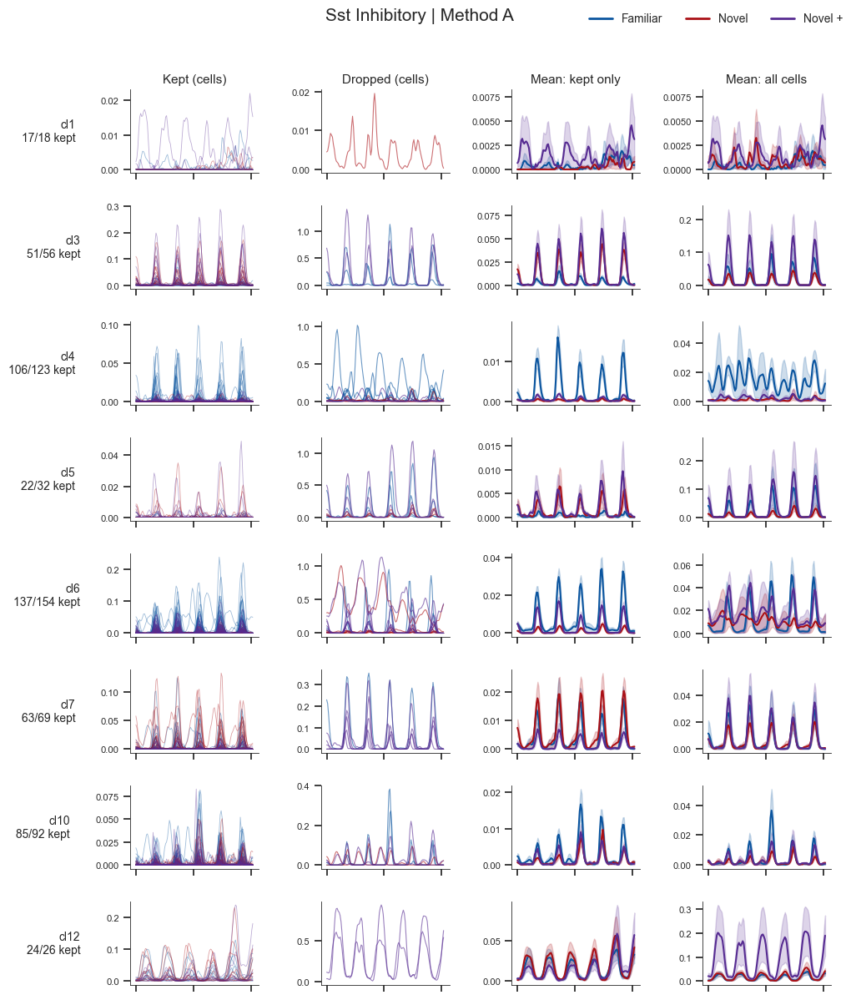

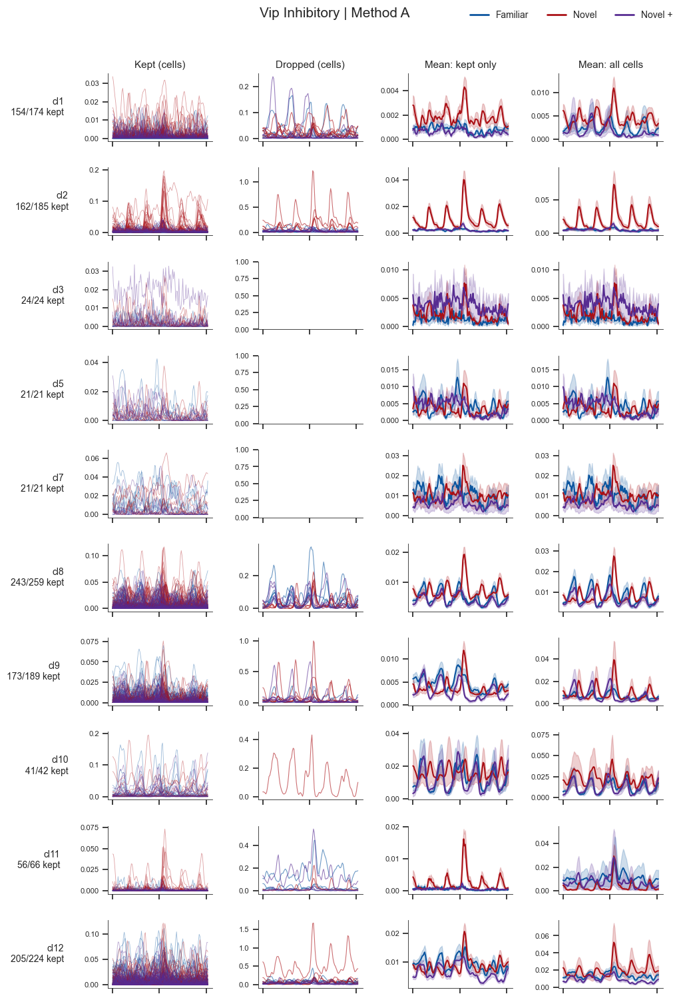

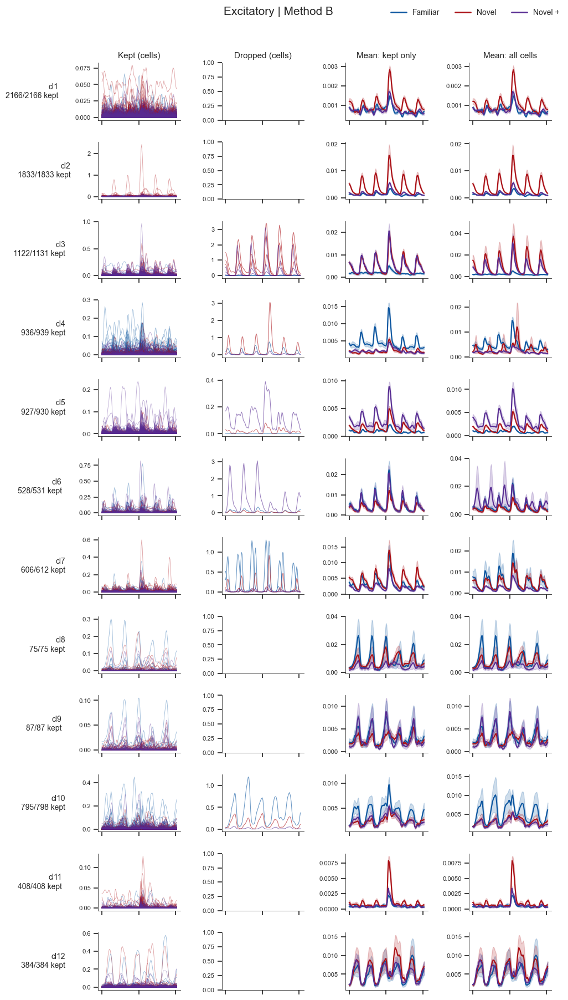

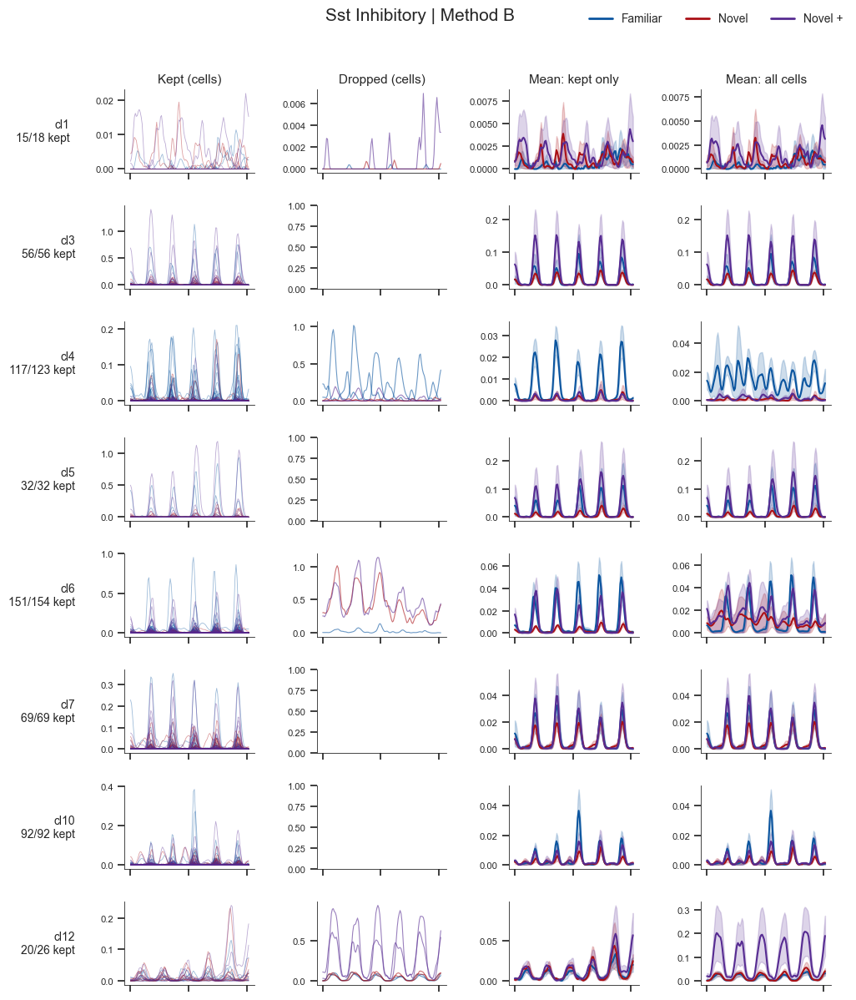

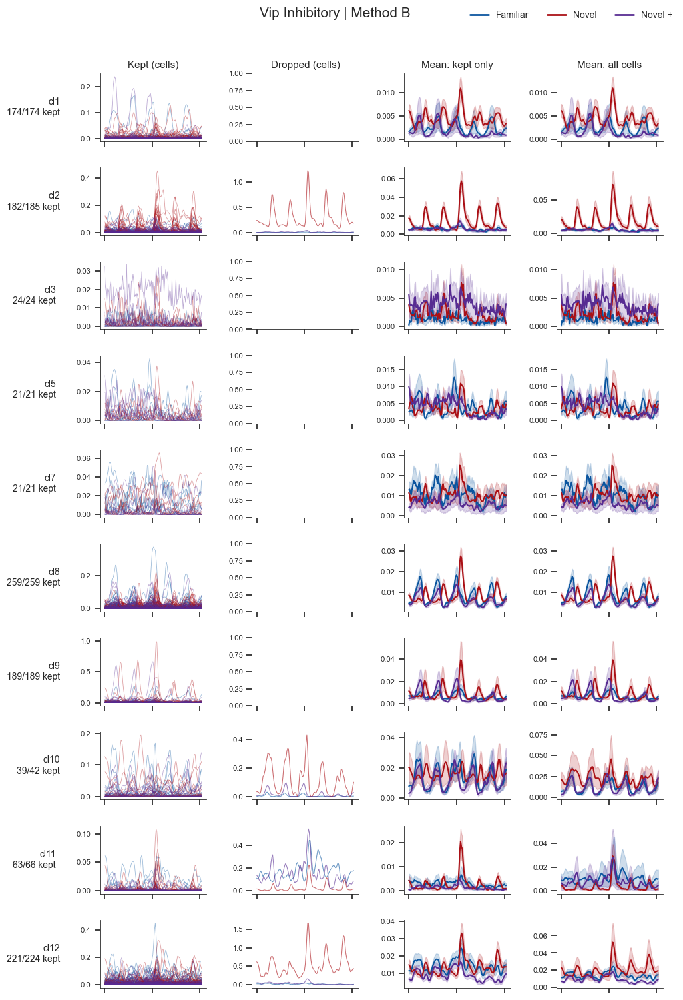

In [13]:
def _keep_mask(g, method, B, peaks, outlier_threshold, peak_threshold):
    """Boolean keep-mask for one reset-indexed subgroup g (single cell_type, cluster).
    A = MAD on trace peak (per experience level); B = global percentile set;
    C = fixed absolute threshold on trace peak amplitude."""
    if method == 'A':
        keep = np.ones(len(g), bool)
        for _, sub in g.groupby('experience_level'):
            pos = sub.index.values
            p = peaks[pos]
            med = np.median(p); mad = np.median(np.abs(p - med))
            if mad > 0:
                keep[pos] = p <= med + outlier_threshold * 1.4826 * mad
        return keep
    if method == 'C':
        return peaks <= peak_threshold
    return ~g.cell_specimen_id.isin(B).values


def plot_kept_vs_dropped_by_experience(mdf, cell_type, method='A',
                                       outlier_threshold=5, threshold_percentile=99.8,
                                       peak_threshold=0.5, fill_sem=True):
    """Per-cell-type figure: rows = clusters; cols = kept cells | dropped cells |
    mean of kept | mean of all. Each panel autoscales independently; traces colored by experience level."""
    valid = mdf[[t is not None and not (isinstance(t, float) and np.isnan(t))
                 for t in mdf['mean_trace'].values]].copy()
    valid = valid[valid[['cluster_id', 'cell_type', 'experience_level']].notna().all(axis=1)]
    valid = valid[valid.cell_type == cell_type]
    if len(valid) == 0:
        print(f"no data for {cell_type}"); return
    ts = np.asarray(valid['trace_timestamps'].values[0])

    exp_colors = utils.get_experience_level_colors()
    available = valid.experience_level.unique()
    ordered_exp = [l for l in experience_levels if l in available]
    color_map = {lvl: exp_colors[i % len(exp_colors)] for i, lvl in enumerate(ordered_exp)}

    B = method_B_drops(mdf, threshold_percentile) if method == 'B' else None
    clusters = sorted(valid.cluster_id.unique())

    nrows, ncols = len(clusters), 4
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 1.5 * nrows),
                             sharex=True, squeeze=False)
    for j, tt in enumerate(['Kept (cells)', 'Dropped (cells)', 'Mean: kept only', 'Mean: all cells']):
        axes[0, j].set_title(tt, fontsize=11)

    for i, cl in enumerate(clusters):
        g = valid[valid.cluster_id == cl].reset_index(drop=True)
        peaks = np.array([np.nanmax(np.abs(np.asarray(t))) for t in g['mean_trace'].values])
        keep = _keep_mask(g, method, B, peaks, outlier_threshold, peak_threshold)
        traces = np.vstack([np.asarray(t) for t in g['mean_trace'].values])
        ax_keep, ax_drop, ax_mk, ax_all = axes[i]

        for exp in ordered_exp:
            em = (g.experience_level.values == exp)
            col = color_map[exp]
            for t in traces[em & keep]:
                ax_keep.plot(ts, t, color=col, alpha=0.4, lw=0.6)
            for t in traces[em & ~keep]:
                ax_drop.plot(ts, t, color=col, alpha=0.6, lw=0.8)
            kk = traces[em & keep]
            if len(kk):
                m = kk.mean(0); ax_mk.plot(ts, m, color=col, lw=1.5)
                if fill_sem and len(kk) > 1:
                    s = kk.std(0) / np.sqrt(len(kk)); ax_mk.fill_between(ts, m - s, m + s, color=col, alpha=0.2)
            aa = traces[em]
            if len(aa):
                m = aa.mean(0); ax_all.plot(ts, m, color=col, lw=1.5)
                if fill_sem and len(aa) > 1:
                    s = aa.std(0) / np.sqrt(len(aa)); ax_all.fill_between(ts, m - s, m + s, color=col, alpha=0.2)

        ax_keep.set_ylabel(f"cl{int(cl)}\n{int(keep.sum())}/{len(g)} kept",
                           fontsize=10, rotation=0, ha='right', va='center', labelpad=22)
        for ax in axes[i]:
            ax.tick_params(axis='x', labelbottom=False)  # share x, blank x labels
            ax.tick_params(axis='y', labelsize=8)        # keep y ticks to read range
            for sp in ('top', 'right'):
                ax.spines[sp].set_visible(False)
            for sp in ('left', 'bottom'):
                ax.spines[sp].set_linewidth(0.6)

    handles = [plt.Line2D([0], [0], color=color_map[e], lw=2) for e in ordered_exp]
    fig.legend(handles, ordered_exp, loc='upper right', ncol=len(ordered_exp), fontsize=10,
               frameon=False, bbox_to_anchor=(1.0, 1.01))
    mtag = f"Method {method}" + (f" (peak>{peak_threshold})" if method == 'C' else "")
    fig.suptitle(f"{cell_type} | {mtag}", fontsize=15, y=1.005)
    fig.tight_layout()
    plt.show()


# Choose the response set to inspect (change_mdf / image_mdf / omission_mdf)
mdf = change_mdf
cell_types = sorted(mdf.cell_type.dropna().unique())

# Method A (MAD on trace peak, outlier_threshold=5) — one figure per cell type
for ct in cell_types:
    plot_kept_vs_dropped_by_experience(mdf, ct, method='A')

# Method B (percentile on mean_response & mean_baseline, 99.8) — one figure per cell type
for ct in cell_types:
    plot_kept_vs_dropped_by_experience(mdf, ct, method='B')


In [14]:
# --- Method C: quantify how many cells/traces a fixed peak threshold would drop ---
def method_C_drops(mdf, peak_threshold):
    """Rows (cell x experience) whose mean-trace peak |amplitude| exceeds peak_threshold."""
    v = mdf[[t is not None and not (isinstance(t, float) and np.isnan(t))
             for t in mdf['mean_trace'].values]].copy()
    v['peak_abs'] = [np.nanmax(np.abs(np.asarray(t))) for t in v['mean_trace'].values]
    return v[v.peak_abs > peak_threshold]

mdf = change_mdf   # swap for image_mdf / omission_mdf
tot = mdf.cell_specimen_id.nunique()
print(f"Total cells: {tot}\n")
for thr in [0.4, 0.7]:
    d = method_C_drops(mdf, thr)
    print(f"peak > {thr}: {len(d)} (cell x experience) instances, "
          f"{d.cell_specimen_id.nunique()} unique cells "
          f"({100*d.cell_specimen_id.nunique()/tot:.1f}%)")


Total cells: 3895

peak > 0.4: 48 (cell x experience) instances, 38 unique cells (1.0%)
peak > 0.7: 30 (cell x experience) instances, 24 unique cells (0.6%)


In [15]:
# Per-cluster breakdown for one threshold (cells dropped if peak ever exceeds it)
thr = 0.4
d = method_C_drops(mdf, thr)
per = (d.drop_duplicates(['cell_specimen_id','cell_type','cluster_id'])
        .groupby(['cell_type','cluster_id']).size().rename('C_dropped'))
totals = (mdf.drop_duplicates('cell_specimen_id')
            .groupby(['cell_type','cluster_id']).size().rename('n_cells'))
summary_C = pd.concat([totals, per], axis=1).fillna(0).astype(int)
summary_C['C_frac'] = (summary_C.C_dropped / summary_C.n_cells).round(3)
summary_C.sort_values('C_frac', ascending=False)


n_cells  C_dropped  C_frac
cell_type      cluster_id                            
Sst Inhibitory 5                11          3   0.273
               12                9          2   0.222
               3                19          3   0.158
               6                52          5   0.096
Vip Inhibitory 10               14          1   0.071
               11               22          1   0.045
               9                63          2   0.032
               2                62          2   0.032
               12               75          2   0.027
Sst Inhibitory 4                41          1   0.024
Excitatory     6               177          3   0.017
               7               204          3   0.015
               3               377          5   0.013
               10              266          2   0.008
               12              128          1   0.008
               4               313          1   0.003
               2               611          1   0.002
               9                29          0   0.000
               8                25          0   0.000
Sst Inhibitory 7                23          0   0.000
               10               31          0   0.000
Excitatory     11              136          0   0.000
Vip Inhibitory 1                60          0   0.000
Sst Inhibitory 1                 6          0   0.000
Vip Inhibitory 3                 8          0   0.000
               5                 7          0   0.000
               7                 7          0   0.000
               8                87          0   0.000
Excitatory     5               310          0   0.000
               1               722          0   0.000

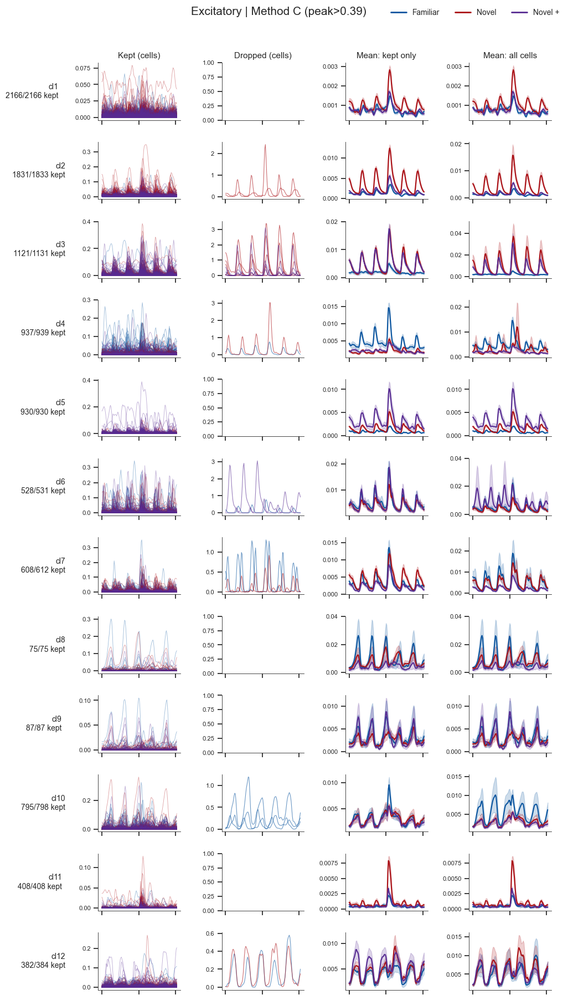

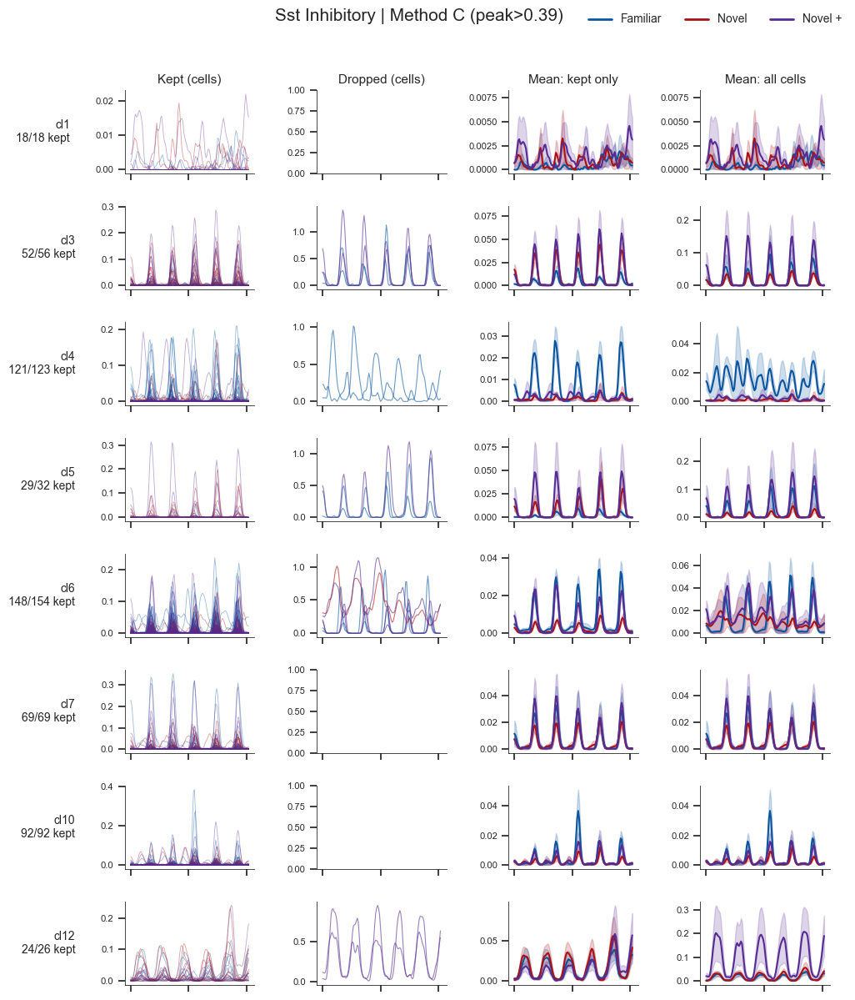

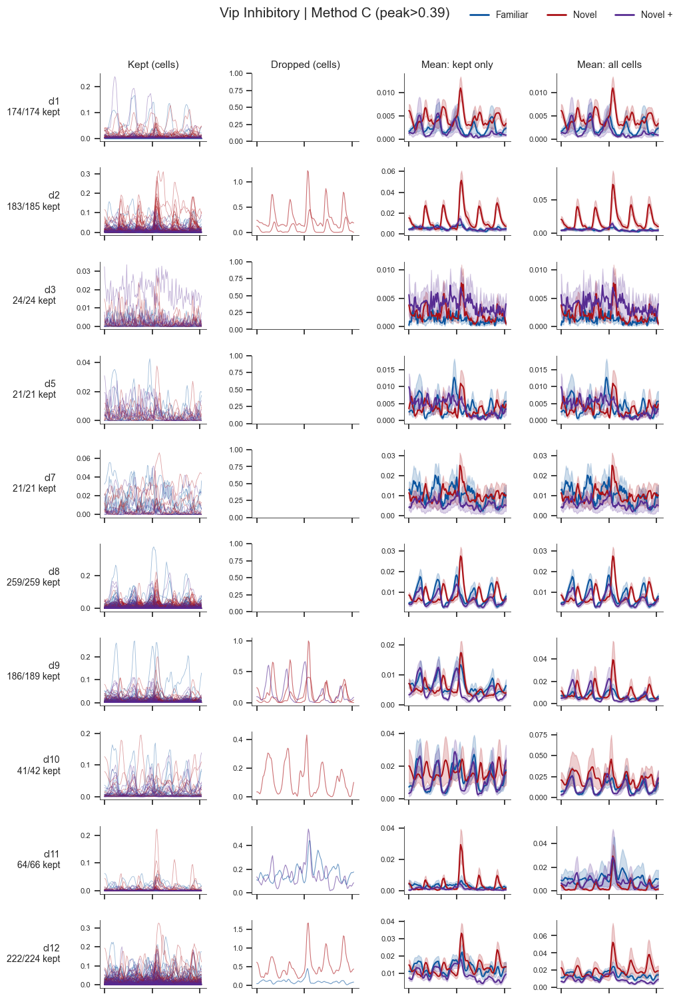

In [16]:
# Kept vs. dropped comparison using Method C (reuses plot_kept_vs_dropped_by_experience)
mdf = change_mdf
peak_threshold = 0.39   # try 0.7 as well
for ct in sorted(mdf.cell_type.dropna().unique()):
    plot_kept_vs_dropped_by_experience(mdf, ct, method='C', peak_threshold=peak_threshold)


In [17]:
### Sst cluster 4 cells >0.2

In [18]:
def add_peak_abs(mdf):
    """Rows (cell x experience) whose mean-trace peak |amplitude| exceeds peak_threshold."""
    mdf = mdf[[t is not None and not (isinstance(t, float) and np.isnan(t))
             for t in mdf['mean_trace'].values]].copy()
    mdf['peak_abs'] = [np.nanmax(np.abs(np.asarray(t))) for t in mdf['mean_trace'].values]
    return mdf

In [19]:
mdf = add_peak_abs(mdf)

In [20]:
tmp = mdf[(mdf.cell_type=='Sst Inhibitory') & (mdf.cluster_id==4) & (mdf.peak_abs>0.25)]
tmp[['cell_specimen_id','experience_level','peak_abs']].sort_values('peak_abs', ascending=False)

,cell_specimen_id,experience_level,peak_abs
3030,1120094237,Familiar,1.011809
4761,1086580238,Familiar,0.390350


In [21]:
1086557434, 1086547630

(1086557434, 1086547630)

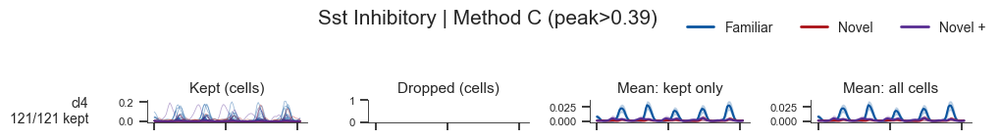

In [22]:
tmp = mdf[(mdf.cell_type=='Sst Inhibitory') & (mdf.cluster_id==4) & (mdf.peak_abs<0.25)]

plot_kept_vs_dropped_by_experience(tmp, 'Sst Inhibitory', method='C', peak_threshold=.39)

In [23]:
import numpy as np, pandas as pd
thr = 0.4
peak = lambda t: np.nanmax(np.abs(np.asarray(t)))
pool = pd.concat([image_mdf, change_mdf, omission_mdf])
pool = pool[[t is not None and not (isinstance(t,float) and np.isnan(t)) for t in pool.mean_trace.values]].copy()
pool['peak'] = pool.mean_trace.apply(peak)

print('library (global per-cell, pooled):', pool.loc[pool.peak>thr,'cell_specimen_id'].nunique(), 'unique cells')
print('per-trace instances exceeding (pooled):', int((pool.peak>thr).sum()))
for name, df in [('image',image_mdf),('change',change_mdf),('omission',omission_mdf)]:
    d = df[[t is not None and not (isinstance(t,float) and np.isnan(t)) for t in df.mean_trace.values]].copy()
    d['peak'] = d.mean_trace.apply(peak)
    print(f'{name}: {int((d.peak>thr).sum())} traces over thr, {d.loc[d.peak>thr,"cell_specimen_id"].nunique()} unique cells')

library (global per-cell, pooled): 43 unique cells
per-trace instances exceeding (pooled): 129
image: 31 traces over thr, 23 unique cells
change: 48 traces over thr, 38 unique cells
omission: 50 traces over thr, 39 unique cells


#### Compare scopes: off vs global vs trace

`apply_peak_threshold` turns Method C on; `peak_scope` picks how cells are dropped:
`'global'` removes a cell from every panel if its peak exceeds 0.4 anywhere (pooled across image/change/omission); `'trace'` drops only the individual rows whose own peak exceeds 0.4 (identical to the Method C grid above). Restart the kernel / reload modules first.

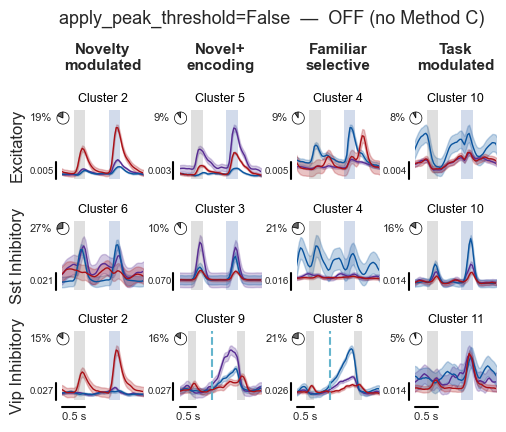

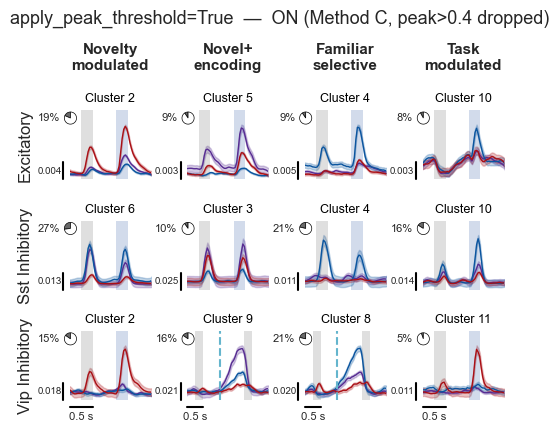

In [24]:
for flag, label in [(False, 'OFF (no Method C)'), (True, 'ON (Method C, peak>0.4 dropped)')]:
    fig, _ = plotting.plot_mean_cluster_response_profiles(
        image_mdf, change_mdf, omission_mdf,
        linewidth=1, x_sb_seconds=0.5,
        # isolate Method C as the only filter
        apply_peak_threshold=flag,
    )
    fig.suptitle(f'apply_peak_threshold={flag}  —  {label}', y=1.04, fontsize=13)
    plt.show()


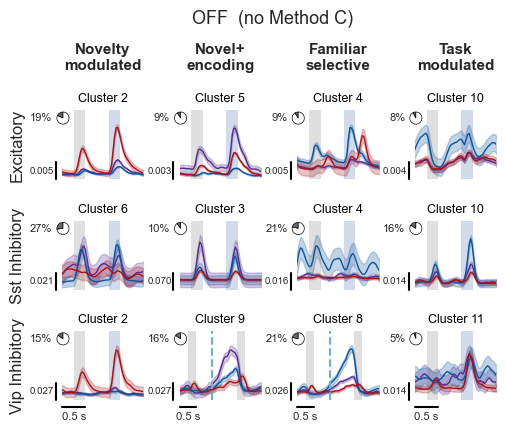

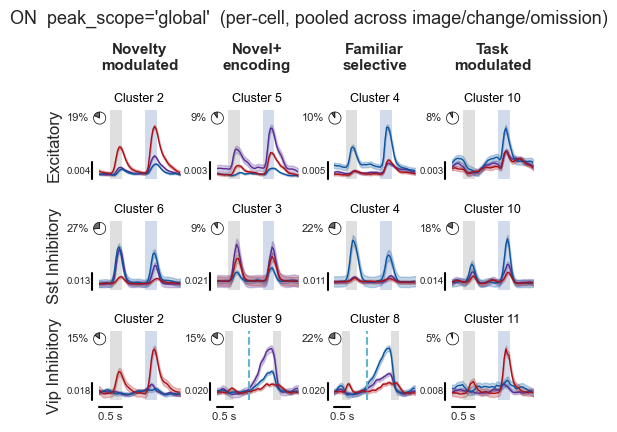

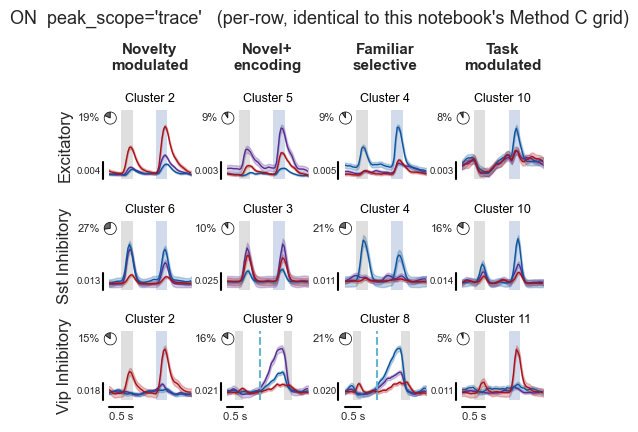

In [25]:
# Compare: OFF vs Method C global (per-cell, pooled) vs Method C trace (per-row = eval grid).
# No MAD outlier_threshold anymore; peak-threshold scope is the only difference.
configs = [
    dict(apply_peak_threshold=False,                      label='OFF  (no Method C)'),
    dict(apply_peak_threshold=True, peak_scope='global',  label="ON  peak_scope='global'  (per-cell, pooled across image/change/omission)"),
    dict(apply_peak_threshold=True, peak_scope='trace',   label="ON  peak_scope='trace'   (per-row, identical to this notebook's Method C grid)"),
]
for cfg in configs:
    label = cfg.pop('label')
    fig, _ = plotting.plot_mean_cluster_response_profiles(
        image_mdf, change_mdf, omission_mdf,
        linewidth=1, x_sb_seconds=0.5, **cfg)
    fig.suptitle(label, y=1.04, fontsize=13)
    plt.show()
